A chart is often the first and the last thing in a piece of quant research: first to *see* the data before modelling it, last to *show* the result to someone who will decide on it. A good chart reveals a bug in seconds (a price that jumps because of an unadjusted split, a backtest that is suspiciously smooth); a bad one hides it.

This chapter teaches **Matplotlib**, the foundation that pandas, seaborn and most scientific Python use, then two libraries built on top of the same ideas: **seaborn** for statistical charts in one line, and **Plotly** for interactive charts you can zoom and hover in a browser.

:::eli5
A Matplotlib picture is a sheet of paper (the *figure*) with one or more drawing boxes glued on it (the *axes*). Each box has its own rulers and its own lines, dots and bars. Making a chart is: get a sheet, choose how many boxes, draw in each box, write labels, and save.
:::

## Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as mtick
from pathlib import Path
print("Matplotlib", mpl.__version__)

IMAGES = Path("images"); IMAGES.mkdir(exist_ok=True)
DATA = Path("datasets")
def save_fig(name, fig=None):
    (fig or plt.gcf()).savefig(IMAGES / f"{name}.png", dpi=150, bbox_inches="tight")

def log_axis(ax, fmt="{:g}"):
    """Log y-axis with readable ticks (1, 2, 5, 10, ...) instead of 10^0 notation."""
    ax.set_yscale("log")
    ax.yaxis.set_major_locator(mtick.LogLocator(base=10, subs=(1, 2, 5)))
    ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: fmt.format(v)))
    ax.yaxis.set_minor_formatter(mtick.NullFormatter())

prices = pd.read_csv(DATA / "prices_long.csv", parse_dates=["date"])
close = prices.pivot(index="date", columns="ticker", values="adj_close")
rets = close.pct_change(fill_method=None)
fred = pd.read_csv(DATA / "fred_rates.csv", index_col="date", parse_dates=True)
R = {}
print(close.shape, rets.shape, fred.shape)

Matplotlib 3.11.2
(3983, 10) (3983, 10) (4131, 3)


## The anatomy of a figure

There are two ways to use Matplotlib. The quick **pyplot** style (`plt.plot(...)`) draws on “the current axes”. The **object-oriented** style creates the figure and axes explicitly and calls methods on them. Use the object-oriented style for anything beyond a one-line check: it is unambiguous when there are several panels.

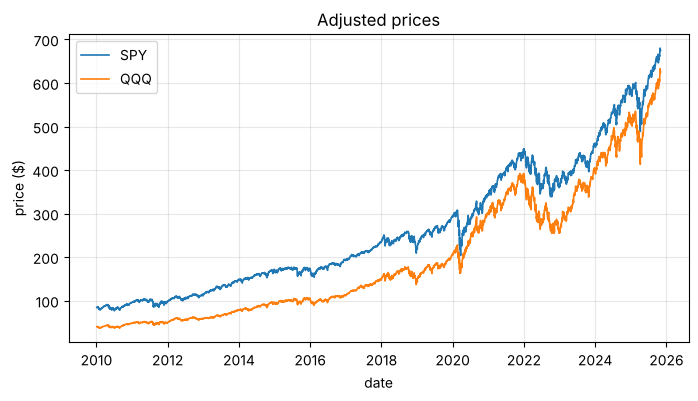

In [2]:
fig, ax = plt.subplots(figsize=(8, 4))            # one figure, one axes
ax.plot(close.index, close["SPY"], lw=1.2, label="SPY")
ax.plot(close.index, close["QQQ"], lw=1.2, label="QQQ")
ax.set_title("Adjusted prices")                   # axes title
ax.set_xlabel("date"); ax.set_ylabel("price ($)")
ax.legend(loc="upper left")
ax.grid(alpha=0.3)
save_fig("first_plot", fig)
plt.show()

![Figure 3-1. The object-oriented recipe: figure and axes, plot, title, labels, legend, grid.](images/first_plot.png)

Everything on the chart is an object you can change: `ax.xaxis`, `ax.spines["top"]`, every tick label, every line returned by `ax.plot`. The vocabulary:

| Object | What it is | How you reach it |
|---|---|---|
| Figure | the whole canvas | `fig`, `fig.suptitle`, `fig.savefig` |
| Axes | one plotting area with its own coordinates | `ax` (from `plt.subplots`) |
| Axis | the x or y ruler of an axes | `ax.xaxis`, `ax.set_xlim`, `ax.set_yscale` |
| Artist | anything drawn: lines, text, patches | returned by `ax.plot`, `ax.text`, … |

## Choosing the right chart

| Question | Chart | Matplotlib |
|---|---|---|
| How does it change over time? | line | `ax.plot` |
| How are two variables related? | scatter | `ax.scatter` |
| How are values distributed? | histogram, box plot | `ax.hist`, `ax.boxplot` |
| How do categories compare? | bar | `ax.bar`, `ax.barh` |
| How do many pairs relate? | heatmap | `ax.imshow`, `ax.pcolormesh` |
| What share is each part? | stacked area | `ax.stackplot` |

### Growth of $1: always compare on a common base

Raw prices are not comparable (SPY trades around 600, GLD around 300). Rebase each series to 1 at the start, and use a **log scale**, on which equal percentage moves have equal heights.

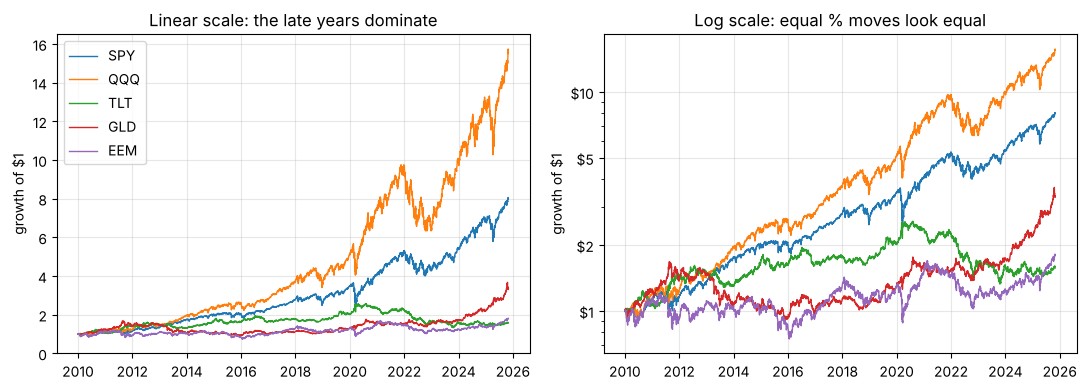

In [3]:
picks = ["SPY", "QQQ", "TLT", "GLD", "EEM"]
growth = close[picks].dropna()
growth = growth / growth.iloc[0]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for t in picks:
    axes[0].plot(growth.index, growth[t], lw=1, label=t)
    axes[1].plot(growth.index, growth[t], lw=1, label=t)
axes[0].set_title("Linear scale: the late years dominate")
axes[1].set_title("Log scale: equal % moves look equal")
log_axis(axes[1], "${:g}")      # helper from the setup cell
for a in axes:
    a.set_ylabel("growth of $1"); a.grid(alpha=0.3)
axes[0].legend()
fig.tight_layout(); save_fig("growth_linear_log", fig)
plt.show()

![Figure 3-2. The same data on linear and log scales. On a linear scale, a 10% move in 2025 looks ten times larger than a 10% move in 2010.](images/growth_linear_log.png)

:::trap
Long price histories on a linear scale exaggerate recent moves and hide early crashes. Use a log y-axis for anything that compounds: prices, wealth curves, index levels.
:::

### Distributions: histogram against the normal curve

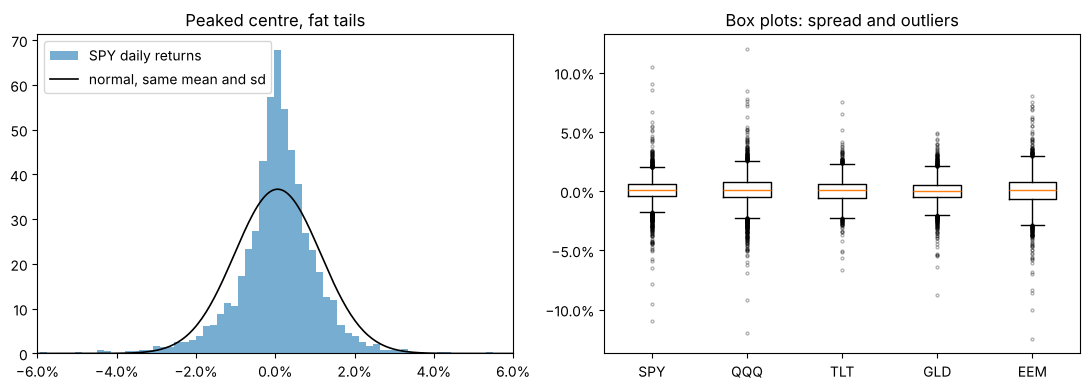

In [4]:
r = rets["SPY"].dropna()
mu, sd = r.mean(), r.std()
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(r, bins=120, density=True, alpha=0.6, label="SPY daily returns")
x = np.linspace(r.min(), r.max(), 400)
axes[0].plot(x, np.exp(-0.5 * ((x - mu) / sd) ** 2) / (sd * np.sqrt(2 * np.pi)), "k", lw=1.2, label="normal, same mean and sd")
axes[0].set_xlim(-0.06, 0.06); axes[0].legend(); axes[0].set_title("Peaked centre, fat tails")
axes[0].xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
axes[1].boxplot([rets[t].dropna() for t in picks], tick_labels=picks, showfliers=True, flierprops={"markersize": 2, "alpha": 0.3})
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(1.0)); axes[1].set_title("Box plots: spread and outliers")
fig.tight_layout(); save_fig("distributions", fig)
plt.show()
R["n_4sd"] = int((np.abs(r - mu) > 4 * sd).sum())
R["n_4sd_normal"] = f"{len(r) * 2 * 3.17e-5:.1f}"

![Figure 3-3. Real returns have a taller peak and fatter tails than a normal distribution with the same mean and standard deviation.](images/distributions.png)

SPY had 28 days with moves beyond four standard deviations; a normal distribution would predict about 0.3. Financial ML Chapter 1 measures these fat tails properly.

### Scatter plots and a fitted line

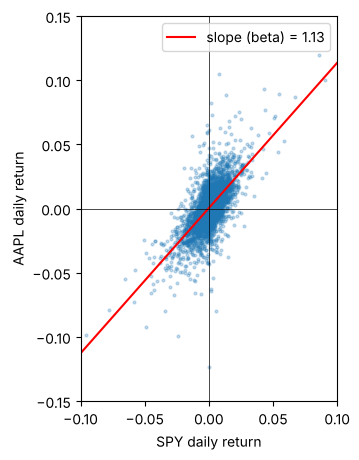

In [5]:
pair = rets[["SPY", "AAPL"]].dropna()
beta, alpha = np.polyfit(pair["SPY"], pair["AAPL"], 1)
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.scatter(pair["SPY"], pair["AAPL"], s=4, alpha=0.25)
xs = np.array([-0.1, 0.1])
ax.plot(xs, alpha + beta * xs, "r", lw=1.5, label=f"slope (beta) = {beta:.2f}")
ax.axhline(0, color="k", lw=0.5); ax.axvline(0, color="k", lw=0.5)
ax.set_xlim(-0.1, 0.1); ax.set_ylim(-0.15, 0.15)
ax.set_xlabel("SPY daily return"); ax.set_ylabel("AAPL daily return"); ax.legend()
ax.set_aspect("equal", adjustable="box")
save_fig("scatter_beta", fig)
plt.show()
R["beta"] = f"{beta:.2f}"

![Figure 3-4. Each dot is one day. The slope of the fitted line is Apple’s beta to the market.](images/scatter_beta.png)

Apple's beta over the sample is 1.13: on average it moves 1.13% for every 1% move of the market.

### Bars: annual returns

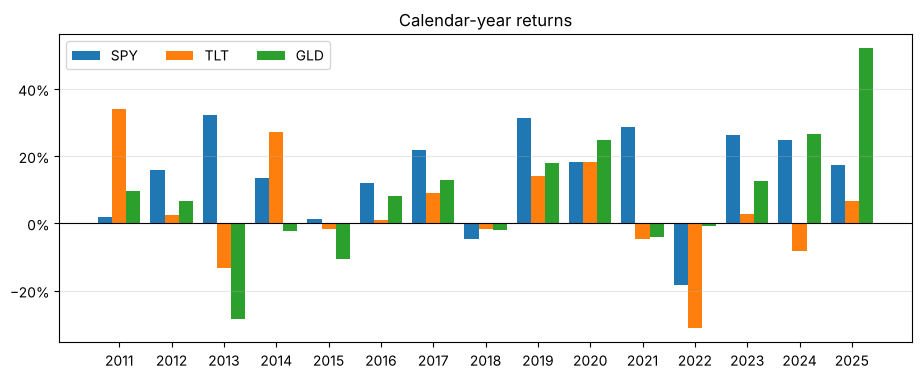

In [6]:
annual = close[["SPY", "TLT", "GLD"]].resample("YE").last().pct_change(fill_method=None).dropna()
annual.index = annual.index.year
fig, ax = plt.subplots(figsize=(11, 4))
w = 0.27
x = np.arange(len(annual))
for i, t in enumerate(annual.columns):
    ax.bar(x + (i - 1) * w, annual[t], width=w, label=t)
ax.set_xticks(x, annual.index, rotation=0)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.axhline(0, color="k", lw=0.8); ax.legend(ncols=3); ax.set_title("Calendar-year returns")
ax.grid(axis="y", alpha=0.3)
save_fig("annual_bars", fig)
plt.show()

![Figure 3-5. Grouped bars: in most years bonds (TLT) or gold (GLD) did something different from stocks, but in 2022 stocks and bonds both fell.](images/annual_bars.png)

## Several panels: `subplots`, shared axes and `GridSpec`

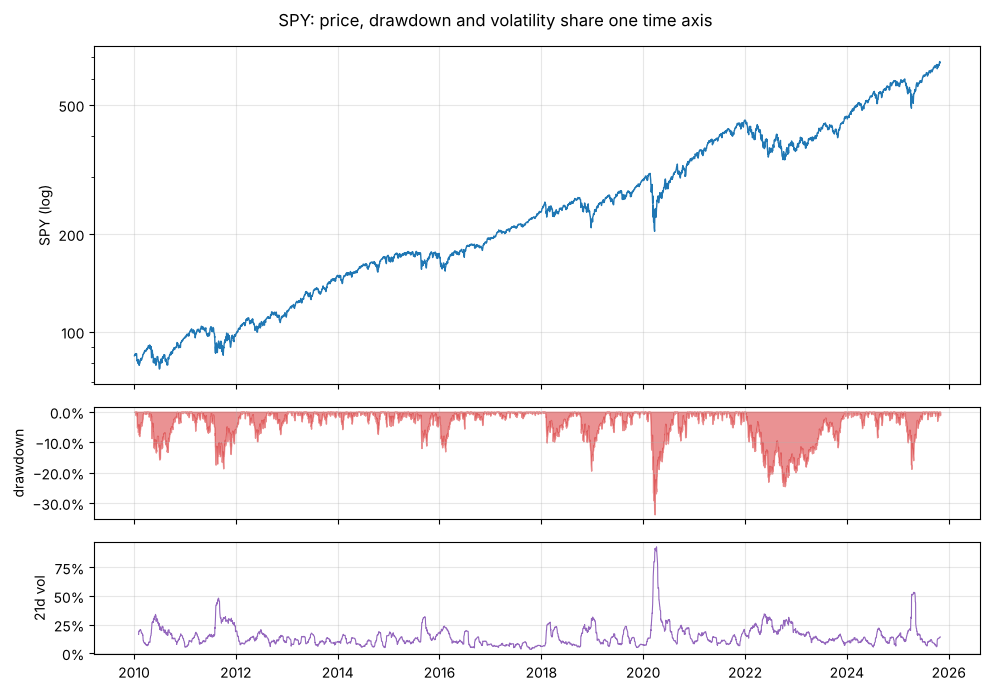

In [7]:
spy = close["SPY"]
dd = spy / spy.cummax() - 1
vol = rets["SPY"].rolling(21).std() * np.sqrt(252)

fig, axes = plt.subplots(3, 1, figsize=(10, 7), sharex=True, gridspec_kw={"height_ratios": [3, 1, 1]})
axes[0].plot(spy, lw=1); log_axis(axes[0]); axes[0].set_ylabel("SPY (log)")
axes[1].fill_between(dd.index, dd, 0, color="tab:red", alpha=0.5); axes[1].set_ylabel("drawdown")
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
axes[2].plot(vol, lw=0.8, color="tab:purple"); axes[2].set_ylabel("21d vol")
axes[2].yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
axes[2].xaxis.set_major_locator(mdates.YearLocator(2))
axes[2].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
for a in axes:
    a.grid(alpha=0.3)
fig.suptitle("SPY: price, drawdown and volatility share one time axis")
fig.tight_layout(); save_fig("three_panel", fig)
plt.show()

![Figure 3-6. Stacked panels with a shared date axis: crashes, drawdowns and volatility spikes line up vertically.](images/three_panel.png)

`sharex=True` keeps zooming and ticks consistent; `height_ratios` gives the main series more room; `mdates.YearLocator` and `DateFormatter` control date ticks. For irregular layouts, `fig.add_gridspec` or `plt.subplot_mosaic("AAB;CCB")` place panels of different sizes.

## Annotations, twin axes and reference lines

A chart for a decision-maker should point at the thing that matters.

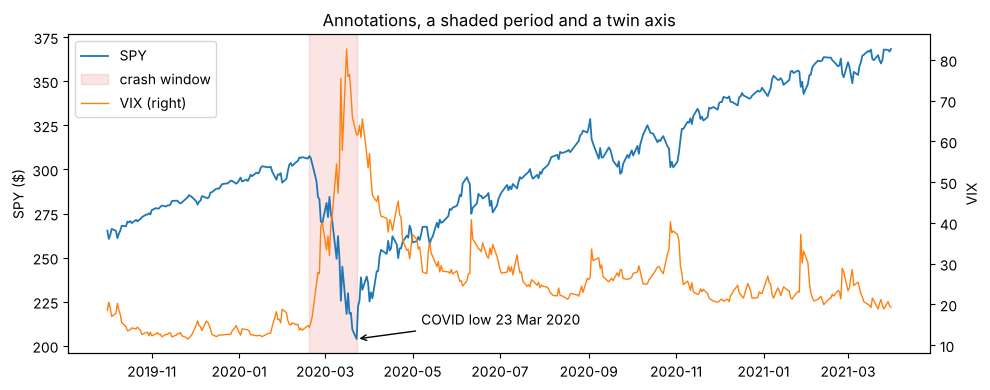

In [8]:
s = close["SPY"].loc["2019-10":"2021-03"]
low_date, low = s.idxmin(), s.min()
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(s, lw=1.3, label="SPY")
ax.annotate(f"COVID low {low_date:%d %b %Y}", xy=(low_date, low), xytext=(low_date + pd.Timedelta(days=45), low * 1.04),
            arrowprops=dict(arrowstyle="->"), fontsize=10)
ax.axvspan(pd.Timestamp("2020-02-19"), pd.Timestamp("2020-03-23"), color="tab:red", alpha=0.12, label="crash window")
ax2 = ax.twinx()                                     # a second y-axis on the right
ax2.plot(fred.loc[s.index[0]:s.index[-1], "VIXCLS"].dropna(), color="tab:orange", lw=1, label="VIX (right)")
ax2.set_ylabel("VIX")
lines = ax.get_legend_handles_labels(); lines2 = ax2.get_legend_handles_labels()
ax.legend(lines[0] + lines2[0], lines[1] + lines2[1], loc="upper left")
ax.set_ylabel("SPY ($)"); ax.set_title("Annotations, a shaded period and a twin axis")
fig.tight_layout(); save_fig("annotate_twin", fig)
plt.show()

![Figure 3-7. The 2020 crash: an annotation, a shaded window and the VIX on a second axis.](images/annotate_twin.png)

:::trap
Twin y-axes let you make any two series look correlated by choosing the scales. Use them only for context (like the VIX here), never to argue that two things move together. For that, plot a scatter or a rolling correlation.
:::

## Heatmaps: a correlation matrix

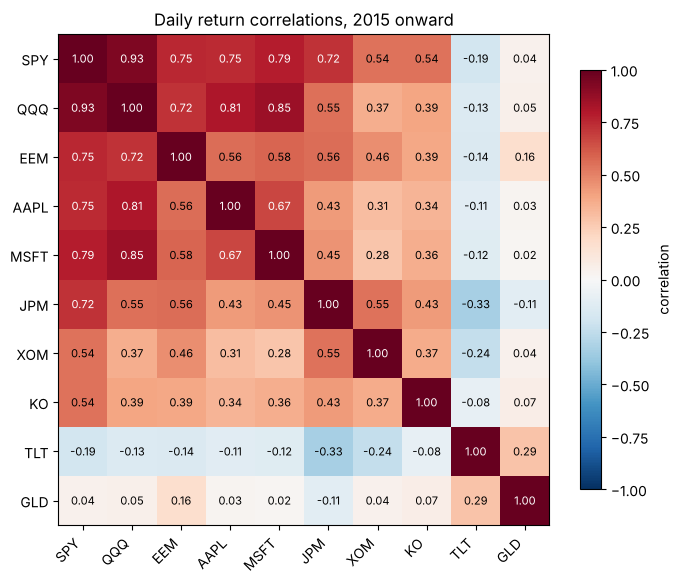

In [9]:
corr = rets[["SPY", "QQQ", "EEM", "AAPL", "MSFT", "JPM", "XOM", "KO", "TLT", "GLD"]].loc["2015":].corr()
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)      # diverging map centred at 0
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr)), corr.index)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(corr.iloc[i, j]) > 0.6 else "black")
fig.colorbar(im, ax=ax, shrink=0.8, label="correlation")
ax.set_title("Daily return correlations, 2015 onward")
fig.tight_layout(); save_fig("corr_heatmap", fig)
plt.show()

![Figure 3-8. A correlation heatmap with a diverging colour map fixed to [−1, 1]. Stocks cluster together; bonds and gold are the diversifiers.](images/corr_heatmap.png)

:::tip
Choose the colour map by the meaning of the data. **Sequential** maps (`viridis`, `Blues`) for values from low to high, **diverging** maps (`RdBu_r`, `coolwarm`) for values around a meaningful centre such as 0, **qualitative** maps (`tab10`) for categories. Fix `vmin` and `vmax` so two heatmaps are comparable. Avoid `jet` and rainbow maps: they invent edges that are not in the data and fail for colour-blind readers.
:::

## Style: make the data the loudest thing

['Solarize_Light2', 'bmh', 'classic', 'dark_background', 'fast', 'fivethirtyeight', 'ggplot', 'grayscale'] ...


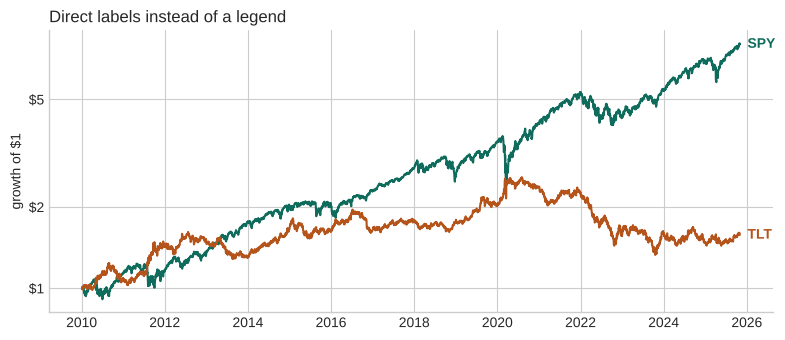

In [10]:
print(plt.style.available[:8], "...")
with plt.style.context("seaborn-v0_8-whitegrid"):
    fig, ax = plt.subplots(figsize=(8, 3.5))
    ax.plot(growth["SPY"], lw=1.5, color="#0f6b5c")
    ax.plot(growth["TLT"], lw=1.5, color="#b4531a")
    for t, c in [("SPY", "#0f6b5c"), ("TLT", "#b4531a")]:
        ax.text(growth.index[-1], growth[t].iloc[-1], f"  {t}", color=c, va="center", fontweight="bold")
    ax.spines[["top", "right"]].set_visible(False)
    log_axis(ax, "${:g}"); ax.set_ylabel("growth of $1")
    ax.set_title("Direct labels instead of a legend", loc="left")
    fig.tight_layout(); save_fig("styled", fig)
    plt.show()

![Figure 3-9. A cleaner chart: direct labels, no top and right spines, a left-aligned title.](images/styled.png)

The habits that make charts honest and readable: label axes with units, start bar charts at zero, use a log scale for compounding series, label lines directly when there are only a few, keep colours consistent across a report (SPY is always the same colour), and remove everything that does not carry information.

## Saving figures

In [11]:
fig, ax = plt.subplots(figsize=(4, 3))
ax.plot([1, 2, 3], [1, 4, 9])
fig.savefig(IMAGES / "demo.png", dpi=200, bbox_inches="tight")   # raster, for web pages and slides
fig.savefig(IMAGES / "demo.svg", bbox_inches="tight")            # vector, sharp at any zoom
plt.close(fig)                                                   # free memory in loops
import os
print(sorted(p.name for p in IMAGES.glob("demo.*")))
for p in IMAGES.glob("demo.*"):
    os.remove(p)

['demo.png', 'demo.svg']


Use PNG at 150–200 dpi for screens, SVG or PDF for papers. When you make hundreds of charts in a loop, call `plt.close(fig)` each time.

## pandas plotting: the quick look

pandas DataFrames have a `.plot` method that calls Matplotlib for you. It is perfect for a first look and returns an axes you can keep customising.

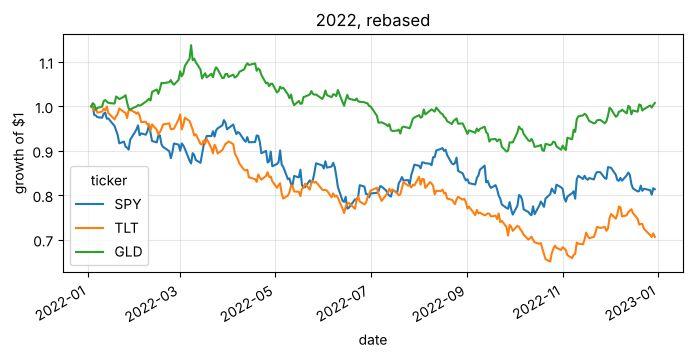

In [12]:
ax = close[["SPY", "TLT", "GLD"]].loc["2022"].pipe(lambda d: d / d.iloc[0]).plot(figsize=(8, 3.5), title="2022, rebased")
ax.set_ylabel("growth of $1"); ax.grid(alpha=0.3)
save_fig("pandas_plot", ax.figure)
plt.show()

![Figure 3-10. One line of pandas: 2022, the year stocks and bonds fell together.](images/pandas_plot.png)

## seaborn: statistical charts in one line

seaborn works best with **long** (tidy) data: one row per observation, with columns for the variables you want to map to x, y, colour and panels.

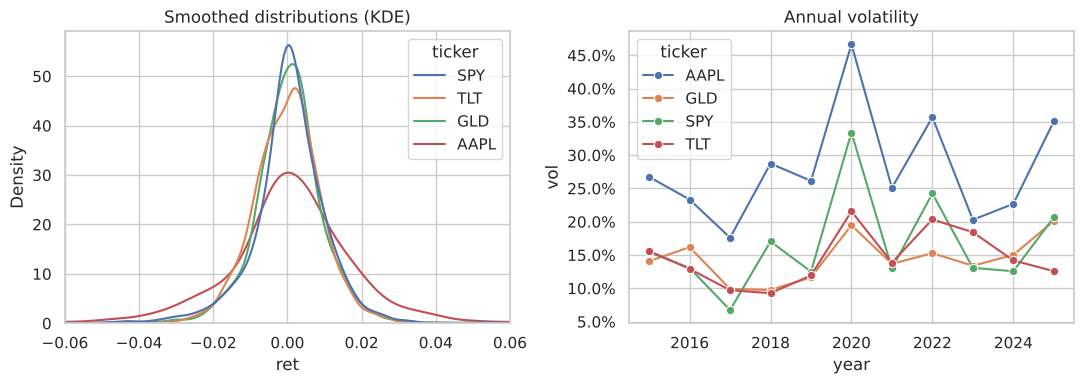

In [13]:
import seaborn as sns
sns.set_theme(style="whitegrid", context="notebook")
tidy = (rets[["SPY", "TLT", "GLD", "AAPL"]].loc["2015":]
        .melt(ignore_index=False, var_name="ticker", value_name="ret").dropna().reset_index())
tidy["year"] = tidy["date"].dt.year
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.kdeplot(data=tidy, x="ret", hue="ticker", ax=axes[0], clip=(-0.06, 0.06), common_norm=False)
axes[0].set_xlim(-0.06, 0.06); axes[0].set_title("Smoothed distributions (KDE)")
vol_year = tidy.groupby(["year", "ticker"])["ret"].std().mul(np.sqrt(252)).reset_index(name="vol")
sns.lineplot(data=vol_year, x="year", y="vol", hue="ticker", marker="o", ax=axes[1])
axes[1].set_title("Annual volatility"); axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
fig.tight_layout(); save_fig("seaborn_kde_line", fig)
plt.show()

![Figure 3-11. seaborn maps columns to colours automatically: distributions (left) and yearly volatility (right).](images/seaborn_kde_line.png)

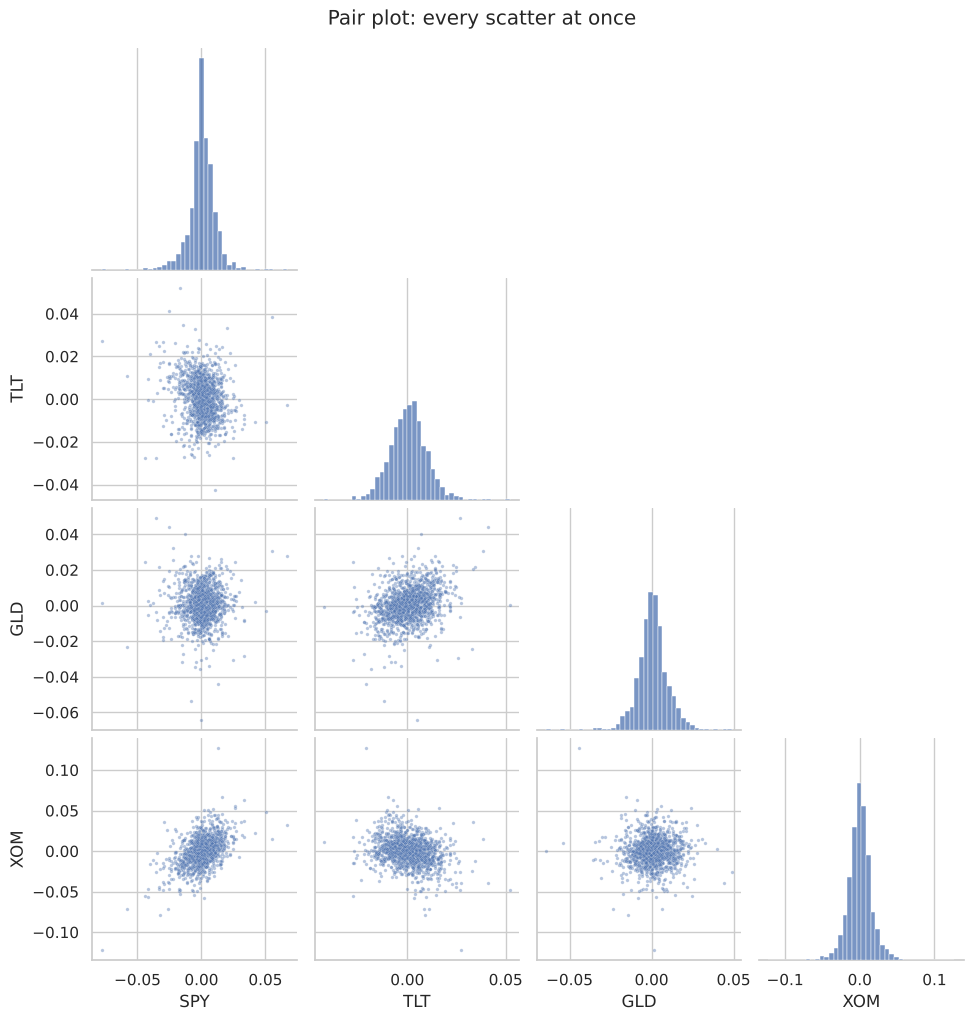

In [14]:
g = sns.pairplot(rets[["SPY", "TLT", "GLD", "XOM"]].loc["2015":].dropna().sample(1500, random_state=0),
                 corner=True, plot_kws={"s": 6, "alpha": 0.4}, diag_kws={"bins": 40})
g.figure.suptitle("Pair plot: every scatter at once", y=1.02)
save_fig("pairplot", g.figure)
plt.show()
mpl.rcParams.update(mpl.rcParamsDefault)        # back to Matplotlib's defaults

![Figure 3-12. A pair plot shows all pairwise scatters and each distribution, a fast way to explore a new dataset.](images/pairplot.png)

## Plotly: interactive charts for the browser

Plotly draws charts in the browser: you can zoom, pan, hover to read values, and toggle series. It is the usual choice for dashboards. Below we build a candlestick chart with volume and a moving average, and save it as an HTML page; it is the playground of this chapter.

In [15]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots

d = prices[prices.ticker == "SPY"].set_index("date").loc["2024-06":"2025-10"]
d = d.assign(ma50=d["close"].rolling(50).mean())
figp = make_subplots(rows=2, cols=1, shared_xaxes=True, row_heights=[0.75, 0.25], vertical_spacing=0.03)
figp.add_trace(go.Candlestick(x=d.index, open=d.open, high=d.high, low=d.low, close=d.close, name="SPY"), row=1, col=1)
figp.add_trace(go.Scatter(x=d.index, y=d.ma50, name="50-day MA", line=dict(width=1.5)), row=1, col=1)
figp.add_trace(go.Bar(x=d.index, y=d.volume, name="volume", marker_color="rgba(100,110,130,.5)"), row=2, col=1)
figp.update_layout(height=560, margin=dict(l=40, r=20, t=80, b=30), title="SPY daily candles (drag to zoom, double-click to reset)",
                   xaxis_rangeslider_visible=False, template="plotly_white",
                   legend=dict(orientation="h", y=1.02, yanchor="bottom", x=1, xanchor="right"))
figp.update_xaxes(rangebreaks=[dict(bounds=["sat", "mon"])])         # hide weekends
Path("animations").mkdir(exist_ok=True)
figp.write_html("animations/spy_candles.html", include_plotlyjs="cdn", full_html=True)
print("saved animations/spy_candles.html")

saved animations/spy_candles.html


::playground animations/spy_candles.html 600

Each candle shows a day's open, high, low and close: the body spans open to close (green if the close is higher), the thin wick spans the low to the high. Hover over a candle to read the four prices.

:::quant
Matplotlib for reports, papers and anything you save as an image; Plotly when someone needs to explore the chart; seaborn when you want a statistical chart of tidy data quickly. All three accept pandas objects, so the same DataFrame feeds all of them.
:::

## Animations

Matplotlib's `FuncAnimation` redraws a figure frame by frame and saves the result as a GIF or MP4. Here: how one year of daily returns builds a wealth curve, day by day, for a random strategy against the market.

In [16]:
from matplotlib.animation import FuncAnimation, PillowWriter
yr = rets["SPY"].loc["2024"].dropna()
rng = np.random.default_rng(1)
coin = np.where(rng.random(len(yr)) < 0.5, 1, -1)            # a coin-flip long/short strategy
w_mkt, w_coin = (1 + yr).cumprod(), (1 + coin * yr).cumprod()

fig, ax = plt.subplots(figsize=(7, 3.6))
l1, = ax.plot([], [], lw=1.8, label="buy and hold SPY")
l2, = ax.plot([], [], lw=1.8, label="coin-flip long/short")
ax.set_xlim(yr.index[0], yr.index[-1]); ax.set_ylim(0.8, 1.35)
ax.axhline(1, color="k", lw=0.6); ax.legend(loc="upper left"); ax.set_ylabel("growth of $1")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
title = ax.set_title("")
def update(k):
    l1.set_data(yr.index[:k], w_mkt.iloc[:k]); l2.set_data(yr.index[:k], w_coin.iloc[:k])
    title.set_text(f"2024, day {k}")
    return l1, l2, title
anim = FuncAnimation(fig, update, frames=range(1, len(yr) + 1, 3), interval=60, blit=False)
anim.save(IMAGES / "wealth_race.gif", writer=PillowWriter(fps=18))
plt.close(fig)
print("frames:", len(range(1, len(yr) + 1, 3)))

frames: 84


![Figure 3-13. An animation saved as a GIF: a year of buy-and-hold against a coin-flip strategy, drawn day by day.](images/wealth_race.gif)

## Putting it together: a one-page market report

The final figure combines everything: a mosaic layout, a log-scale growth chart with direct labels, a drawdown panel, a heatmap and a bar chart, consistent colours and a title that states the finding.

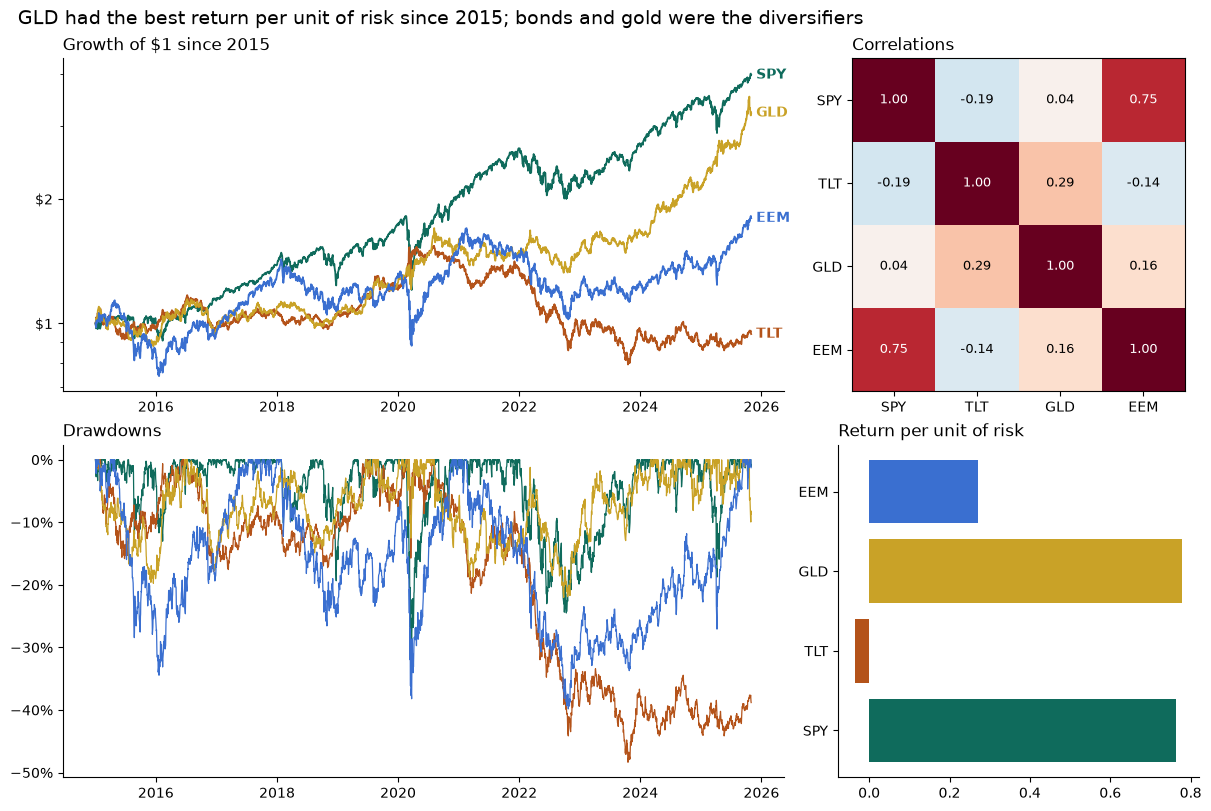

         CAGR    vol  max DD  return/vol
ticker                                  
SPY     0.136  0.179  -0.337       0.764
TLT    -0.005  0.151  -0.484      -0.036
GLD     0.114  0.147  -0.220       0.780
EEM     0.056  0.205  -0.398       0.271


In [17]:
assets = ["SPY", "TLT", "GLD", "EEM"]
colors = dict(zip(assets, ["#0f6b5c", "#b4531a", "#c9a227", "#3a6fd0"]))
g = close[assets].loc["2015":].dropna(); g = g / g.iloc[0]
rr = rets[assets].loc["2015":].dropna()
stats = pd.DataFrame({
    "CAGR": g.iloc[-1] ** (252 / len(g)) - 1,
    "vol": rr.std() * np.sqrt(252),
    "max DD": (g / g.cummax() - 1).min(),
})
stats["return/vol"] = stats["CAGR"] / stats["vol"]

fig = plt.figure(figsize=(12, 8), layout="constrained")
axd = fig.subplot_mosaic("AAB;CCD")
a = axd["A"]
for t in assets:
    a.plot(g[t], color=colors[t], lw=1.3); a.text(g.index[-1], g[t].iloc[-1], f" {t}", color=colors[t], fontweight="bold", va="center")
log_axis(a, "${:g}"); a.set_title("Growth of $1 since 2015", loc="left"); a.spines[["top", "right"]].set_visible(False)
c = axd["C"]
for t in assets:
    c.plot(g[t] / g[t].cummax() - 1, color=colors[t], lw=0.9)
c.yaxis.set_major_formatter(mtick.PercentFormatter(1.0)); c.set_title("Drawdowns", loc="left"); c.spines[["top", "right"]].set_visible(False)
b = axd["B"]
cm = rr.corr()
b.imshow(cm, cmap="RdBu_r", vmin=-1, vmax=1)
b.set_xticks(range(4), assets); b.set_yticks(range(4), assets)
for i in range(4):
    for j in range(4):
        b.text(j, i, f"{cm.iloc[i, j]:.2f}", ha="center", va="center", fontsize=9,
               color="white" if abs(cm.iloc[i, j]) > 0.6 else "black")
b.set_title("Correlations", loc="left")
dax = axd["D"]
dax.barh(stats.index, stats["return/vol"], color=[colors[t] for t in stats.index])
dax.set_title("Return per unit of risk", loc="left"); dax.spines[["top", "right"]].set_visible(False)
best = stats["return/vol"].idxmax()
fig.suptitle(f"{best} had the best return per unit of risk since 2015; bonds and gold were the diversifiers", fontsize=14, x=0.01, ha="left")
save_fig("market_report", fig)
plt.show()
print(stats.round(3))

![Figure 3-14. A one-page report: one finding in the title, consistent colours, four views of the same assets.](images/market_report.png)

## Exercises

:::exercise
1. Plot the 10-year Treasury yield (`fred["DGS10"]`) and the 3-month bill rate on one axes, shade the periods when the 3-month rate was above the 10-year (an *inverted yield curve*), and annotate the first day of the longest inversion.
2. Make a 2 × 5 grid of histograms of daily returns, one per ticker, with shared x-axes and the annualised volatility written in each panel's title.
3. Draw a **monthly returns heatmap** for SPY: rows are years, columns are months, colours are returns with a diverging map centred at 0, and numbers in each cell.
4. With Plotly, make an interactive line chart of rolling 63-day correlations between SPY and each of TLT, GLD and EEM, and save it as HTML.
5. Improve Figure 3-2: use direct labels, consistent colours, and a title that states the main finding.
:::

<details><summary>Solutions</summary>

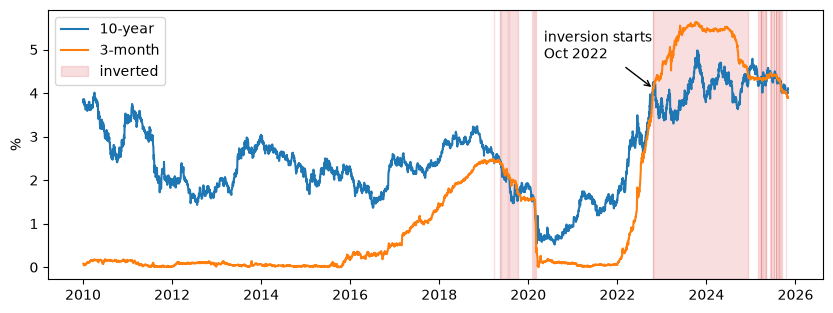

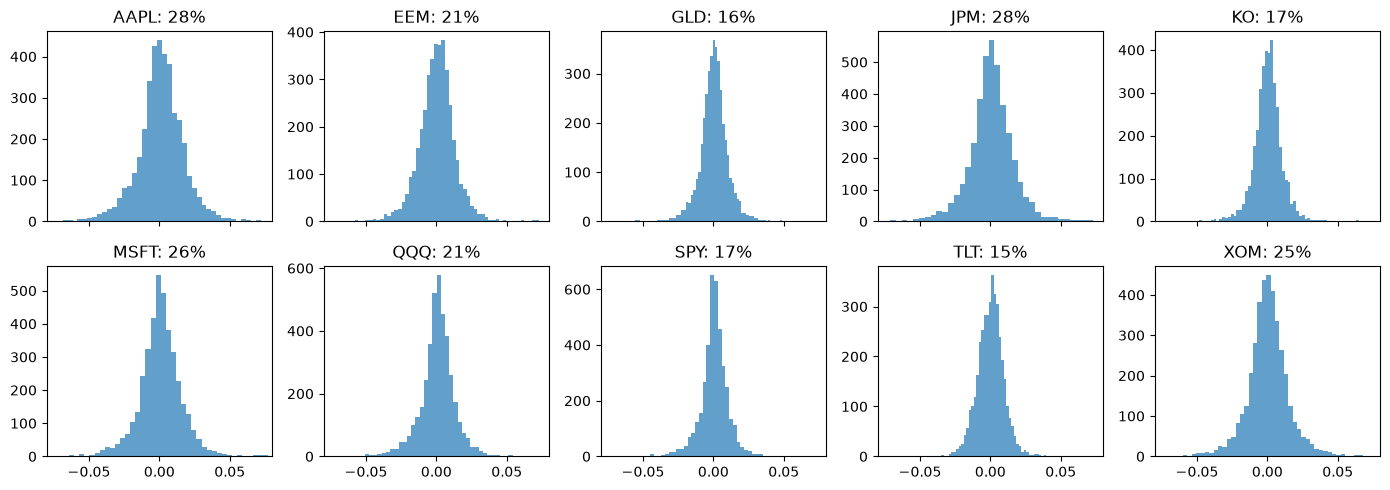

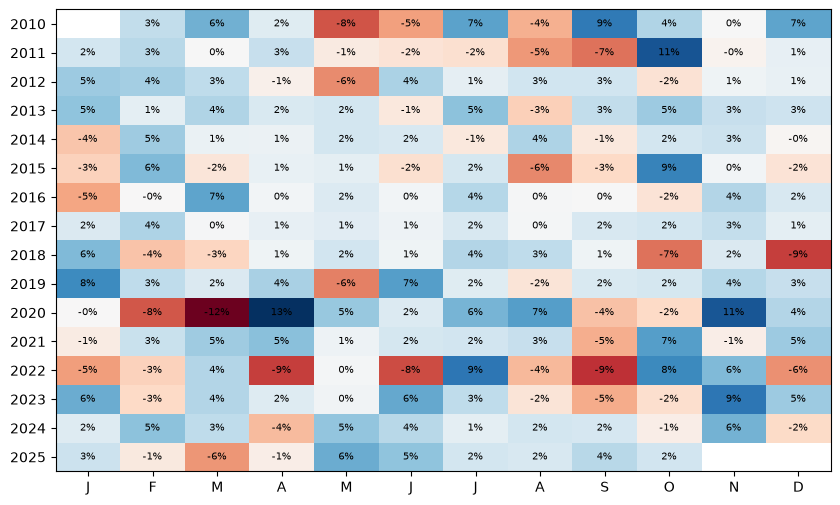

In [18]:
# 1
y = fred[["DGS3MO", "DGS10"]].dropna()
inv = y["DGS3MO"] > y["DGS10"]
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(y["DGS10"], label="10-year"); ax.plot(y["DGS3MO"], label="3-month")
ax.fill_between(y.index, 0, 1, where=inv, transform=ax.get_xaxis_transform(), color="tab:red", alpha=0.15, label="inverted")
runs = (inv != inv.shift()).cumsum()
longest = inv.groupby(runs).sum().idxmax()
start = inv[runs == longest].index[0]
ax.annotate(f"inversion starts\n{start:%b %Y}", xy=(start, y.loc[start, "DGS10"]), xytext=(start - pd.Timedelta(days=900), 4.8), arrowprops=dict(arrowstyle="->"))
ax.legend(); ax.set_ylabel("%"); plt.show()

# 2
fig, axes = plt.subplots(2, 5, figsize=(14, 5), sharex=True)
for ax, t in zip(axes.ravel(), close.columns):
    x = rets[t].dropna(); ax.hist(x, bins=80, color="tab:blue", alpha=0.7)
    ax.set_title(f"{t}: {x.std()*np.sqrt(252):.0%}"); ax.set_xlim(-0.08, 0.08)
fig.tight_layout(); plt.show()

# 3
m = close["SPY"].resample("ME").last().pct_change(fill_method=None).dropna()
tab = m.groupby([m.index.year, m.index.month]).first().unstack()
fig, ax = plt.subplots(figsize=(10, 6))
lim = np.nanmax(np.abs(tab.values))
ax.imshow(tab, cmap="RdBu", vmin=-lim, vmax=lim, aspect="auto")
ax.set_xticks(range(12), ["J", "F", "M", "A", "M", "J", "J", "A", "S", "O", "N", "D"]); ax.set_yticks(range(len(tab)), tab.index)
for i in range(tab.shape[0]):
    for j in range(tab.shape[1]):
        v = tab.iloc[i, j]
        if pd.notna(v):
            ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=7)
plt.show()

# 4
import plotly.express as px
rc = pd.DataFrame({t: rets["SPY"].rolling(63).corr(rets[t]) for t in ["TLT", "GLD", "EEM"]}).dropna()
px.line(rc, title="63-day correlation with SPY").write_html("animations/exercise_corr.html", include_plotlyjs="cdn")
os.remove("animations/exercise_corr.html")

</details>

## What's next

The toolkit is complete: arrays, tables and charts. Part 2 begins with the statistics of financial returns: what real returns look like, which properties a model must respect, and how to tell a real effect from luck.